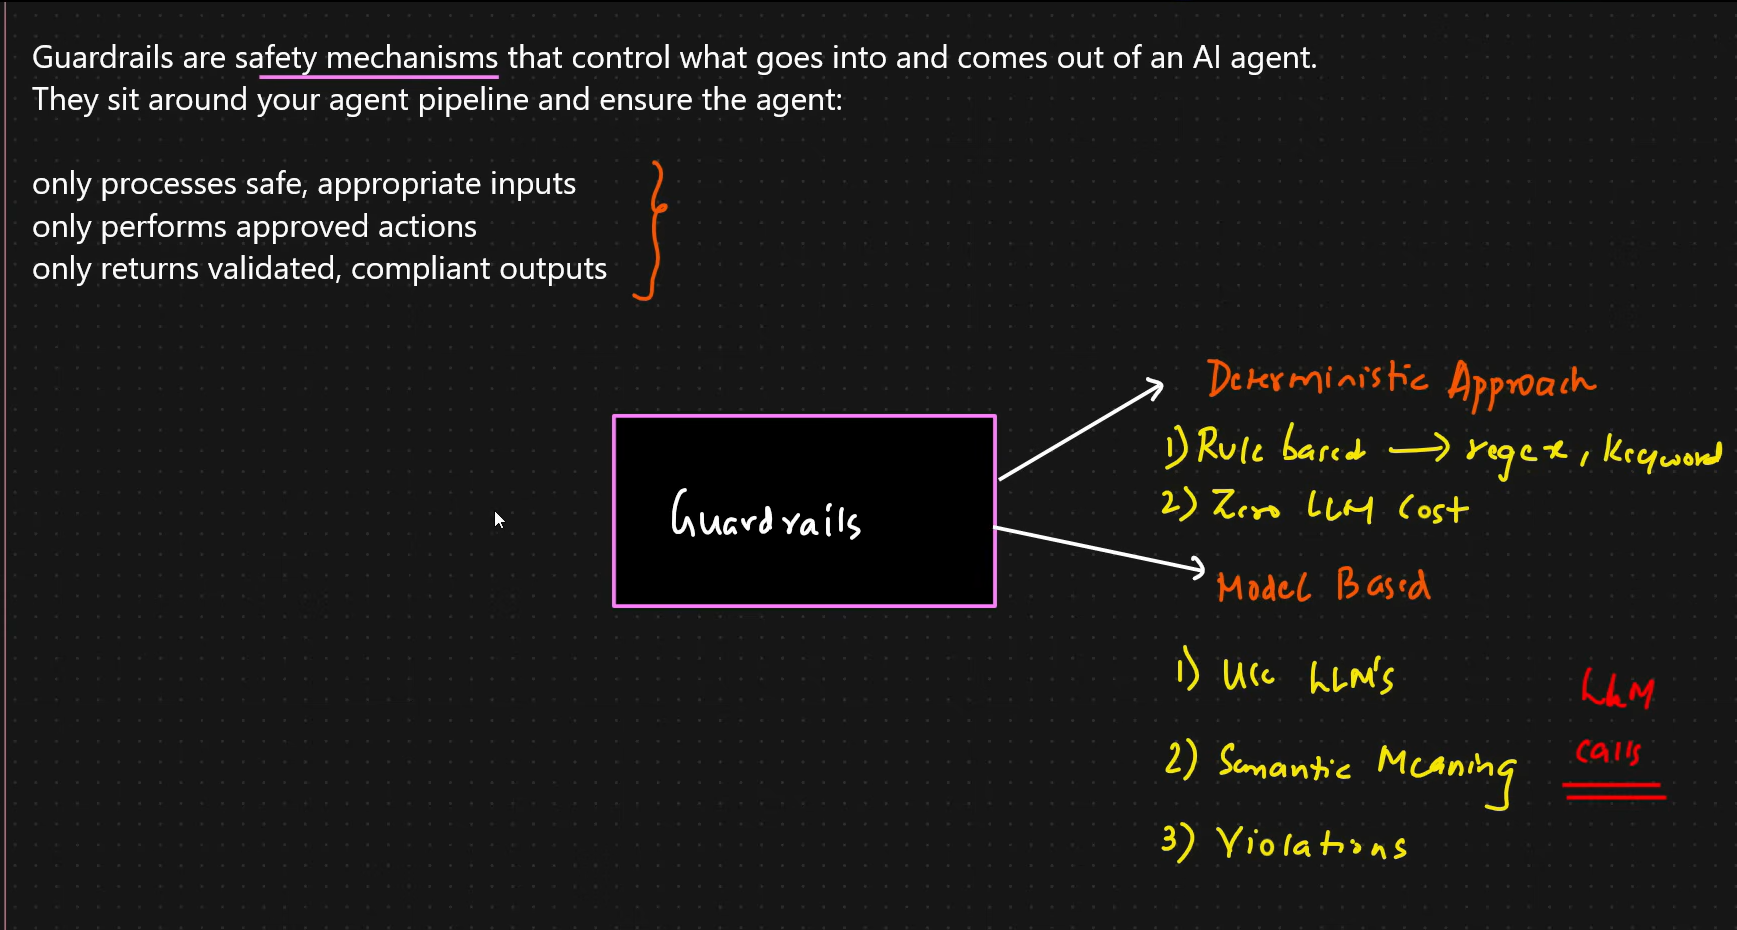

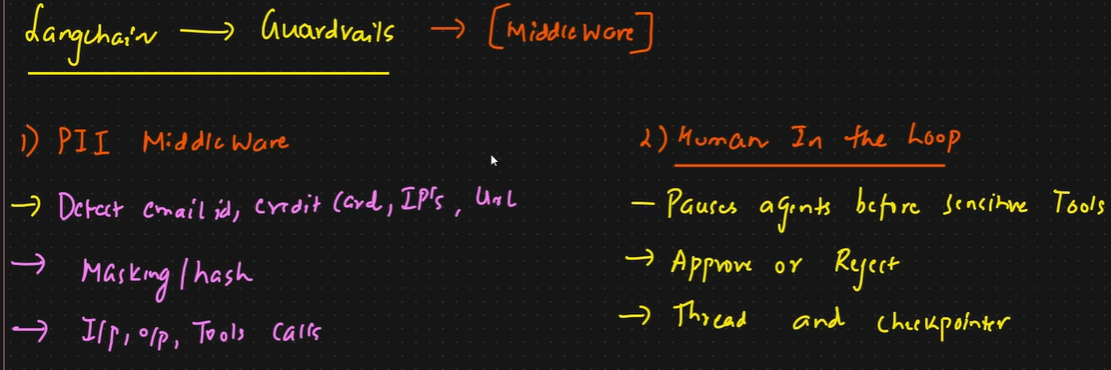

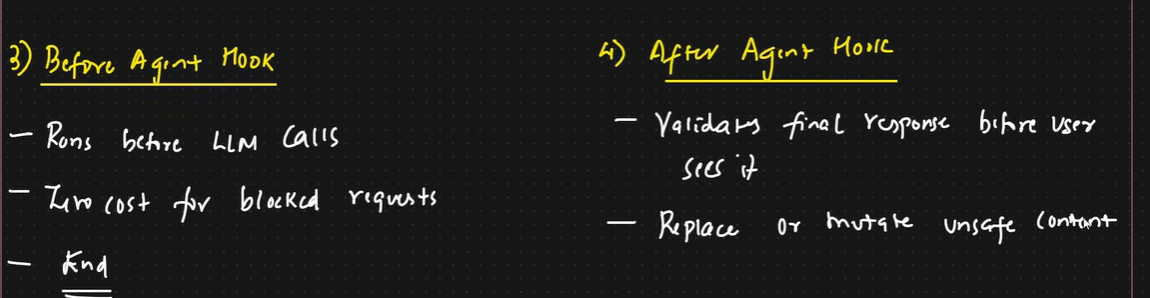


## 🛡️ What You'll Learn: Guardrails in AI Agents

| # | Topic |
|---|-------|
| 1 | What Are Guardrails and Why Do They Matter? |
| 2 | Two Approaches: Deterministic vs. Model-Based Guardrails |
| 3 | Built-In: PII Detection Middleware |
| 4 | Built-In: Human-in-the-Loop Middleware |
| 5 | Custom: Before-Agent Guardrail (Input Filtering) |
| 6 | Custom: After-Agent Guardrail (Output Safety) |
| 7 | Layered and Combined Guardrails |
| 8 | Real-World Use Case: Healthcare Chatbot |



---

## 📝 Summary

| Guardrail Type | Hook | When It Runs | Best For |
|---|---|---|---|
| PII Middleware | Input/Output | During configured processing stages | Data privacy and compliance |
| Human-in-the-Loop | Tool level | Before sensitive tools execute | High-stakes decisions |
| Content Filter | `before_agent` | At the start of agent execution | Blocking unwanted inputs early |
| Safety Validator | `after_agent` | After agent execution | Output quality and safety |
| Custom Logic | Any supported hook | At the configured execution stage | Enforcing business rules |

### 🔑 Key Takeaways

1. **Guardrails Through Middleware** — Implement middleware using the `middleware=[]` parameter in `create_agent()`.

2. **Layer Your Guardrails** — Combine multiple safeguards to provide defense in depth.

3. **Deterministic First, Model-Based Second** — Use inexpensive rule-based checks early to filter straightforward cases before calling an LLM for more nuanced evaluation.

4. **Human-in-the-Loop Requires a Checkpointer** — Use `InMemorySaver` for development and a persistent checkpointer for production workflows.

5. **Custom Middleware Provides Flexibility** — Use hooks such as `before_agent()` and `after_agent()` to implement custom input validation, output safety checks, and business rules.

### Final Takeaway

**Reliable AI agents need multiple layers of protection.** Combine rule-based filtering, PII detection, human approval, and output validation to build safer and more trustworthy AI applications.


In [1]:
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
import os
from getpass import getpass


## 🧠 Section 1: What Are Guardrails?

Guardrails help you build **safe and compliant AI applications** by validating and filtering content at key points during an AI agent's execution.

They can be implemented as **middleware** that intercepts execution at different stages:

- **Before the agent starts:** Input guardrails validate or filter user requests.
- **After the agent completes:** Output guardrails check the agent's response before returning it.
- **Around model and tool calls:** Guardrails inspect interactions with language models and tools.

### Common Use Cases

| Use Case | Example |
|---|---|
| PII Leakage Prevention | Redact email addresses or credit card numbers before logging. |
| Prompt Injection Blocking | Detect and handle adversarial inputs designed to manipulate the agent. |
| Harmful Content Filtering | Block or safely handle dangerous requests. |
| Business Rule Enforcement | Require human approval before executing financial operations. |
| Output Quality Validation | Ensure responses meet defined safety and quality standards. |

### Key Takeaway

**Guardrails act as safety checkpoints throughout an AI agent's workflow.** They help control what enters the system, what actions it takes, and what information it returns.



## ⚖️ Section 2: Two Approaches to Guardrails

### 1. Deterministic Guardrails

Deterministic guardrails use predefined rules and explicit checks to validate inputs, outputs, or actions.

**How they work:**
- Regular expressions (regex)
- Keyword matching
- Conditional statements and explicit rules

**Advantages:**
- ✅ Fast and predictable
- ✅ Cost-effective
- ✅ Easy to test and debug

**Disadvantages:**
- ❌ May miss context-dependent or nuanced violations
- ❌ Can block harmless content if rules are too broad

### 2. Model-Based Guardrails

Model-based guardrails use LLMs or specialized classifiers to understand the meaning and context of content.

**How they work:**
- Analyze the semantic meaning of a request.
- Detect potentially harmful or inappropriate content.
- Evaluate whether a response follows safety policies.

**Advantages:**
- ✅ Better at identifying subtle and context-dependent issues
- ✅ Can handle varied wording and complex situations

**Disadvantages:**
- ❌ Slower than simple rule-based checks
- ❌ More expensive due to model inference
- ❌ May produce inconsistent or incorrect classifications

### Quick Comparison

| Feature | Deterministic | Model-Based |
|---|---|---|
| Method | Explicit rules | Semantic analysis |
| Speed | Usually faster | Usually slower |
| Cost | Usually lower | Usually higher |
| Context understanding | Limited | Better, but imperfect |
| Best suited for | Emails, patterns, fixed rules | Nuanced meaning and intent |

### Key Takeaway

**Use deterministic guardrails for clear rules and model-based guardrails for nuanced decisions.** Combining both approaches can provide stronger protection.


In [6]:

import re

# --- Deterministic Approach ---

def deterministic_approach(text: str) -> bool:
    """
    Checks whether the input contains any banned keywords.
    Returns True if a keyword is found, otherwise False.
    """
    banned_keywords = [
        "hack",
        "malware",
        "phishing",
        "password",
        "credit card",
        "social security number"
    ]

    return any(kw in text.lower() for kw in banned_keywords)


# Test inputs
text_inputs = [
    "I have a credit card number that I want to share.",
    "This is a harmless message.",
    "My social security number is 123-45-6789.",
    "I want to hack into the system."
]

# Check each input
for text in text_inputs:
    blocked = deterministic_approach(text)

    if blocked:
        print(f"Blocked: {text}")
    else:
        print(f"Allowed: {text}")


Blocked: I have a credit card number that I want to share.
Allowed: This is a harmless message.
Blocked: My social security number is 123-45-6789.
Blocked: I want to hack into the system.


In [7]:
from langchain_openai import ChatOpenAI

# --- Model-based approach ---
llm = ChatOpenAI(
    model="prism-ml/ternary-bonsai-2-27b",
    api_key=os.getenv("OPENROUTER_API_KEY"),
    base_url="https://openrouter.ai/api/v1",
    max_tokens=1000,
)

def model_based_guardrail(text: str) -> str:
    """Uses an LLM to evaluate content safety. Returns SAFE or UNSAFE."""
    
    prompt = f"""Is the following user input safe to process? Reply with only 'SAFE' or 'UNSAFE'.

Input: {text}"""
    result = llm.invoke([{"role": "user", "content": prompt}])
    return result.content.strip()

print("=== Model-Based Guardrail Demo ===")
for inp in text_inputs:
    verdict = model_based_guardrail(inp)
    status = "🚫 UNSAFE" if "UNSAFE" in verdict else "✅ SAFE"
    print(f"{status}: {inp}")

=== Model-Based Guardrail Demo ===
🚫 UNSAFE: I have a credit card number that I want to share.
✅ SAFE: This is a harmless message.
🚫 UNSAFE: My social security number is 123-45-6789.
🚫 UNSAFE: I want to hack into the system.



## 🔒 Section 3: Built-in Guardrail — PII Detection Middleware

LangChain provides built-in `PIIMiddleware` for detecting and handling **Personally Identifiable Information (PII)** in AI agent workflows.

PII is information that can identify a person, such as an email address, IP address, or credit card number.

### Supported PII Types

| Type | Example |
|---|---|
| `email` | `user@example.com` |
| `credit_card` | `5105-1051-0510-5100` |
| `ip` | `192.168.1.1` |
| `mac_address` | `00:1A:2B:3C:4D:5E` |
| `url` | `https://secret-site.com` |

### Available Strategies

| Strategy | Result |
|---|---|
| `redact` | Replaces detected PII with a placeholder, such as `[REDACTED_EMAIL]`. |
| `mask` | Hides part of the information, such as `****-****-****-1234`. |
| `hash` | Replaces the value with a hash representation, such as `a8f5f167...`. |
| `block` | Raises an exception when the configured PII is detected. |

### How It Works

1. The agent receives a message or generates a response.
2. `PIIMiddleware` checks the configured content for specified types of PII.
3. The selected strategy determines whether the information is redacted, masked, hashed, or blocked.

### Key Takeaway

**PIIMiddleware helps prevent sensitive personal information from being unnecessarily exposed in AI workflows.**

*Note: Detection depends on the configured PII type and middleware placement. Hashing is not the same as encryption, and PII detection should not be treated as a guarantee that all sensitive information will be caught.*


In [8]:
from langchain.agents import create_agent
from langchain.agents.middleware import PIIMiddleware
from langchain_openai import ChatOpenAI
from langchain_core.tools import tool

# Define a simple dummy tool
@tool
def customer_lookup(query: str) -> str:
    """Look up customer information."""
    return f"Customer record found for query: {query}"

# Create agent with PII Middleware
agent = create_agent(
    model=llm,
    tools=[customer_lookup],
    middleware=[
        # Redact emails in user input before sending to model
        PIIMiddleware(
            "email",
            strategy="redact",
            apply_to_input=True,
        ),
        # Mask credit cards in user input
        PIIMiddleware(
            "credit_card",
            strategy="mask",
            apply_to_input=True,
        ),
        # Block API keys - raise error if detected
        PIIMiddleware(
            "api_key",
            detector=r"sk-[a-zA-Z0-9]{32}",
            strategy="block",
            apply_to_input=True,
        ),
    ],
)

print("Agent with PII middleware created successfully!")

Agent with PII middleware created successfully!


In [9]:
result = agent.invoke({
    "messages": [{
        "role": "user",
        "content": "My email is john.doe@example.com and my card is 5105-1051-0510-5100. Can you help me?"
    }]
})

print("=== Agent Response ===")
print(result["messages"][-1].content)

=== Agent Response ===


I found the account associated with that email, so I can help with your profile.

To point you in the right direction, could you tell me a little more about what you're trying to do? For example:

- A card issue (declined transaction, lost/stolen card, new card order, payment to a merchant that didn't go through)
- Checking a transaction or balance
- Something else

If it's about a card, you're welcome to describe the issue — you don't need to share the full card number or other sensitive details, and I'd advise against sharing passwords or full card numbers in chat.


In [10]:
# Test API Key Blocking
try:
    result = agent.invoke({
        "messages": [{
            "role": "user",
            "content": "Here is my key: sk-abcdefghijklmnopqrstuvwxyz123456"
        }]
    })
    
except Exception as e:
    print(f"🚫 Blocked as expected: {e}")

🚫 Blocked as expected: Detected 1 instance(s) of api_key in text content



## 👤 Section 4: Built-in Guardrail — Human-in-the-Loop Middleware

Human-in-the-loop (HITL) middleware pauses an AI agent's execution before sensitive operations and waits for human review or approval before proceeding.

### How It Works

1. The agent decides to perform a sensitive action.
2. The middleware pauses execution and requests human approval.
3. The human reviews the proposed action.
4. The action is approved, rejected, or modified, depending on the configured workflow.
5. The agent resumes execution when the workflow allows it.

### Best Use Cases

- **Financial transactions:** Require approval before transferring money.
- **Sending emails:** Review emails before sending them to external parties.
- **Deleting production data:** Confirm destructive operations before execution.
- **Business-critical operations:** Add human oversight to actions with significant business impact.

### Key Requirement: Checkpointer

A **checkpointer** is required to persist the agent's state across interruptions so that execution can resume after human input.

For example, LangGraph's `InMemorySaver` can be used for development, while a persistent checkpointer is more suitable for production workflows.

### Key Takeaway

**Human-in-the-loop middleware keeps humans in control of sensitive AI actions.** The agent can perform routine tasks autonomously while important operations require human oversight.


In [11]:
from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command
from langchain_core.tools import tool

@tool
def search_web(query: str) -> str:
    """Search the web for information."""
    return f"Search results for: {query}"

@tool
def send_email(to: str, subject: str, body: str) -> str:
    """Send an email to a recipient."""
    return f"Email sent to {to} with subject: {subject}"

@tool
def delete_records(table: str, condition: str) -> str:
    """Delete records from the database."""
    return f"Deleted records from {table} where {condition}"

# Create agent with HITL middleware
hitl_agent = create_agent(
    model=llm,
    tools=[search_web, send_email, delete_records],
    middleware=[
        HumanInTheLoopMiddleware(
            interrupt_on={
                "send_email": True,       # Require approval
                "delete_records": True,   # Require approval
                "search_web": False,      # Auto-approve
            }
        ),
    ],
    checkpointer=InMemorySaver(),  # Required for state persistence
)

print("Human-in-the-Loop agent created!")

Human-in-the-Loop agent created!


In [12]:
config = {"configurable": {"thread_id": "session_001"}}

result = hitl_agent.invoke(
    {"messages": [{"role": "user", "content": "Send an email to team@company.com about the Q4 results"}]},
    config=config
)

print("=== Agent paused — awaiting human approval ===")
print(result)

=== Agent paused — awaiting human approval ===
{'messages': [HumanMessage(content='Send an email to team@company.com about the Q4 results', additional_kwargs={}, response_metadata={}, id='fe3b6365-1470-47e9-970e-74eb47c68d9e'), AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 1000, 'prompt_tokens': 410, 'total_tokens': 1410, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': 0, 'reasoning_tokens': 1000, 'rejected_prediction_tokens': None, 'text_tokens': None, 'image_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None, 'video_tokens': 0}, 'cost': 0.00053075, 'is_byok': False, 'cost_details': {'upstream_inference_cost': 0.00053075, 'upstream_inference_prompt_cost': 3.075e-05, 'upstream_inference_completions_cost': 0.0005}}, 'model_provider': 'openai', 'model_name': 'prism-ml/ternary-bonsai-2-27b', 'sy

In [14]:
# Step 2: Human reviews and APPROVES
approved_result = hitl_agent.invoke(
    Command(resume={"decisions": [{"type": "approve"}]}),
    config=config   # Same thread_id resumes the paused session
)

print("=== Approved! Final response ===")
print(approved_result["messages"][-1].content)

=== Approved! Final response ===



In [15]:
# Step 3: Alternative — Human REJECTS
config2 = {"configurable": {"thread_id": "session_002"}}

hitl_agent.invoke(
    {"messages": [{"role": "user", "content": "Delete all records from the users table where active=false"}]},
    config=config2
)

rejected_result = hitl_agent.invoke(
    Command(resume={"decisions": [{"type": "reject", "reason": "Too risky, needs DBA review"}]}),
    config=config2
)

print("=== Rejected! Final response ===")
print(rejected_result["messages"][-1].content)

=== Rejected! Final response ===


The request to delete records from the users table where `active=false` was **rejected** and not executed.

If you'd like to proceed with a different approach, please let me know how you'd like to handle this. For example:
- Use a different condition or criteria
- Perform a different operation instead
- Manually review which records should be deleted first



## ⚙️ Section 5: Custom Guardrail — Before-Agent Hook (Input Filter)

Use `before_agent()` to validate, filter, or block user requests **before the AI agent begins processing them**.

This helps prevent invalid, unauthorized, or potentially harmful requests from reaching the agent.

### How It Works

1. A user submits a request.
2. The `before_agent()` hook checks the input against predefined rules.
3. If the request violates a rule, the guardrail blocks it or stops execution.
4. If the request passes validation, the agent continues processing it.

### Best Use Cases

- **Keyword and content filtering:** Block requests containing prohibited terms.
- **Authentication checks:** Verify that a user is authorized to access the system.
- **Rate limiting:** Restrict excessive requests from a user.
- **Request filtering:** Block specific categories of unsupported or prohibited requests.

### Key Takeaway

**Before-agent guardrails control what enters the AI workflow.** They provide an early checkpoint before the agent processes a request.

*Note: The exact hook signature and blocking mechanism depend on the agent framework and middleware version being used.*


In [16]:
from typing import Any
from langchain.agents.middleware import AgentMiddleware, AgentState, hook_config
from langgraph.runtime import Runtime
from langchain.agents import create_agent
from langchain_core.tools import tool

class ContentFilterMiddleware(AgentMiddleware):
    """
    Deterministic guardrail: Block requests containing banned keywords.
    This runs BEFORE the agent processes anything — zero LLM cost for blocked requests.
    """

    def __init__(self, banned_keywords: list[str]):
        super().__init__()
        self.banned_keywords = [kw.lower() for kw in banned_keywords]

    @hook_config(can_jump_to=["end"])
    def before_agent(self, state: AgentState, runtime: Runtime) -> dict[str, Any] | None:
        if not state["messages"]:
            return None

        first_message = state["messages"][0]
        if first_message.type != "human":
            return None

        content = first_message.content.lower()

        for keyword in self.banned_keywords:
            if keyword in content:
                print(f"🚫 Blocked — keyword detected: '{keyword}'")
                return {
                    "messages": [{
                        "role": "assistant",
                        "content": (
                            "I cannot process requests containing inappropriate content. "
                            "Please rephrase your request."
                        )
                    }],
                    "jump_to": "end"
                }
        return None


@tool
def search_tool(query: str) -> str:
    """Search for information."""
    return f"Results for: {query}"


# Create agent with content filter
filtered_agent = create_agent(
    model=llm,
    tools=[search_tool],
    middleware=[
        ContentFilterMiddleware(
            banned_keywords=["hack", "exploit", "malware", "jailbreak", "bypass"]
        ),
    ],
)

print("Content filter agent created!")

Content filter agent created!


In [17]:
# Test 1: Safe request — should pass through
result = filtered_agent.invoke({
    "messages": [{"role": "user", "content": "What is machine learning?"}]
})
print("✅ Safe request response:")
print(result["messages"][-1].content)

✅ Safe request response:


**Machine learning (ML)** is a subset of artificial intelligence (AI) that focuses on building systems that can learn from data and make predictions or decisions without being explicitly programmed for every specific rule.

## Core Idea

Instead of writing instructions like *"if X, then Y,"* you provide a system with examples (data), and it discovers patterns on its own.

## Key Components

- **Data** – The training material (images, text, numbers, sensor readings, etc.)
- **Model/Algorithm** – A mathematical framework that finds patterns in the data (e.g., neural networks, decision trees, support vector machines)
- **Training** – Adjusting the model's parameters using the data to minimize errors
- **Inference/Prediction** – Applying the trained model to new, unseen data

## Common Types

| Type | Description | Example |
|------|-------------|---------|
| **Supervised Learning** | Learn from labeled data | Spam filtering, image classification |
| **Unsupervis

In [18]:
# Test 2: Unsafe request — should be blocked
result = filtered_agent.invoke({
    "messages": [{"role": "user", "content": "How do I hack into a server?"}]
})
print("🚫 Unsafe request response:")
print(result["messages"][-1].content)

🚫 Blocked — keyword detected: 'hack'
🚫 Unsafe request response:
I cannot process requests containing inappropriate content. Please rephrase your request.



## 🔍 Section 6: Custom Guardrail — After-Agent Hook (Output Safety)

Use `after_agent()` to validate, filter, or modify the agent's final response **before it is returned to the user**.

This helps ensure that the generated response meets safety, quality, and compliance requirements.

### How It Works

1. The agent generates a response.
2. The `after_agent()` hook inspects the final output.
3. The guardrail checks the response against defined safety and quality rules.
4. If an issue is detected, the response can be blocked, modified, or replaced with a safe message.
5. The validated response is returned to the user.

### Best Use Cases

- **Model-based safety evaluation:** Detect harmful or inappropriate content in generated responses.
- **Compliance scanning:** Check for required legal, medical, or financial disclaimers.
- **Quality validation:** Ensure responses meet predefined standards for accuracy and completeness.
- **PII protection:** Detect and remove sensitive information that slipped through earlier checks.

### Key Takeaway

**After-agent guardrails control what leaves the AI workflow.** They provide a final checkpoint before the response reaches the user.

*Note: An after-agent hook validates the agent's output, but it does not automatically guarantee factual accuracy or regulatory compliance. The exact implementation depends on the framework and middleware version.*


In [24]:

import os
from dotenv import load_dotenv
from typing import Any

from langchain.agents.middleware import (
    AgentMiddleware,
    AgentState,
    hook_config,
)
from langgraph.runtime import Runtime
from langchain_core.messages import AIMessage
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langchain_core.tools import tool

# Load environment variables
load_dotenv()

# OpenRouter model
llm = ChatOpenAI(
    model="prism-ml/ternary-bonsai-2-27b",
    api_key=os.getenv("OPENROUTER_API_KEY"),
    base_url="https://openrouter.ai/api/v1",
    max_tokens=1000,
    temperature=0,
)

class SafetyGuardrailMiddleware(AgentMiddleware):
    """
    Model-based guardrail that evaluates the agent's
    final response before it reaches the user.
    """

    def __init__(self, safety_model):
        super().__init__()
        # Reuse the configured OpenRouter model
        self.safety_model = safety_model

    @hook_config(can_jump_to=["end"])
    def after_agent(
        self,
        state: AgentState,
        runtime: Runtime
    ) -> dict[str, Any] | None:

        if not state["messages"]:
            return None

        last_message = state["messages"][-1]

        if not isinstance(last_message, AIMessage):
            return None

        safety_prompt = f"""
Evaluate the following AI response for harmful,
unsafe, or inappropriate content.

Respond with exactly one word:
SAFE or UNSAFE.

AI response:
{last_message.content}
"""

        result = self.safety_model.invoke(safety_prompt)
        verdict = result.content.strip().upper()

        if verdict == "UNSAFE":
            print("⚠️ Output flagged as UNSAFE.")

            # Replace the original AI message
            return {
                "messages": [
                    AIMessage(
                        id=last_message.id,
                        content=(
                            "I'm unable to provide that response. "
                            "Please rephrase your request or "
                            "contact support."
                        ),
                    )
                ]
            }

        return None


@tool
def general_tool(query: str) -> str:
    """A general-purpose tool."""
    return f"Tool result: {query}"


# Create the agent with the output safety guardrail
safe_agent = create_agent(
    model=llm,
    tools=[general_tool],
    middleware=[SafetyGuardrailMiddleware(llm)],
)

print("Output safety agent created!")


Output safety agent created!


In [25]:
# Test output safety check
result = safe_agent.invoke({
    "messages": [{"role": "user", "content": "What is the weather like today?"}]
})
print("Response:")
print(result["messages"][-1].content)

Response:


I'd be happy to help with the weather, but I'll need a bit more information:

1. **What's your location?** (City, or ZIP/postal code)
2. **Do you have a preferred source?** (e.g., a specific weather service)

Once you share your location, I can try to look up the current conditions for you. In the meantime, you can also quickly check:
- **weather.gov** (US)
- **weather.com**
- Your phone's built-in weather app

Just let me know where you are and I'll do my best! 🌤️
